In [1]:
# ============================================================
# MEMBER 5 — MACHINE LEARNING & FINAL REPORT
# STEPS 71–90
# ============================================================

# Prerequisite: Run Member 2 first. This script loads the cleaned dataset,
# then trains and evaluates models and saves the model/report.

import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid')

INPUT_FILE = (r"C:\Users\admin\OneDrive\Desktop\Hotel Booking Cancellation Prediction & Analysis\output\preprocessing_results\hotel_bookings_cleaned.csv")
OUTPUT_FOLDER = 'output'
PREPROCESSING_FOLDER = os.path.join(OUTPUT_FOLDER, 'preprocessing_results')
EDA_FOLDER = os.path.join(OUTPUT_FOLDER, 'eda_results')
VISUALIZATION_FOLDER = os.path.join(OUTPUT_FOLDER, 'visualization_results')
ML_FOLDER = os.path.join(OUTPUT_FOLDER, 'machine_learning_results')
for folder in [OUTPUT_FOLDER, PREPROCESSING_FOLDER, EDA_FOLDER, VISUALIZATION_FOLDER, ML_FOLDER]:
    os.makedirs(folder, exist_ok=True)

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, average_precision_score, classification_report, confusion_matrix, ConfusionMatrixDisplay, RocCurveDisplay, PrecisionRecallDisplay)
CLEANED_FILE = os.path.join(PREPROCESSING_FOLDER, 'hotel_bookings_cleaned.csv')
if not os.path.exists(CLEANED_FILE):
    raise FileNotFoundError('Run Member 2 first; cleaned dataset not found: ' + CLEANED_FILE)
df = pd.read_csv(CLEANED_FILE)
target_column = 'is_canceled'

# ============================================================
# STEP 71 — PREPARE MACHINE LEARNING DATASET
# ============================================================

print("\n" + "=" * 70)
print("STEP 71 — PREPARE MACHINE LEARNING DATASET")
print("=" * 70)

ml_df = df.copy()

y = ml_df[target_column].astype(int)

# Remove target and outcome-leaking columns.
# reservation_status reveals the final reservation outcome.
# arrival_date is a derived date; original date components remain available.

columns_to_drop = [
    "is_canceled",
    "reservation_status",
    "reservation_status_date",
    "arrival_date",
    "arrival_month_num",
    "total_guests"
]

X = ml_df.drop(
    columns=[
        col for col in columns_to_drop
        if col in ml_df.columns
    ]
).copy()

print("Feature shape:", X.shape)
print("Target shape:", y.shape)


STEP 71 — PREPARE MACHINE LEARNING DATASET
Feature shape: (119390, 31)
Target shape: (119390,)


In [2]:
# ============================================================
# STEP 72 — IDENTIFY ML FEATURES
# ============================================================

print("\n" + "=" * 70)
print("STEP 72 — IDENTIFY ML FEATURES")
print("=" * 70)

numeric_features = X.select_dtypes(
    include=np.number
).columns.tolist()

categorical_features = X.select_dtypes(
    exclude=np.number
).columns.tolist()

print("Numerical features:", len(numeric_features))
print(numeric_features)

print("\nCategorical features:", len(categorical_features))
print(categorical_features)


STEP 72 — IDENTIFY ML FEATURES
Numerical features: 20
['lead_time', 'arrival_date_year', 'arrival_date_week_number', 'arrival_date_day_of_month', 'stays_in_weekend_nights', 'stays_in_week_nights', 'adults', 'children', 'babies', 'is_repeated_guest', 'previous_cancellations', 'previous_bookings_not_canceled', 'booking_changes', 'agent', 'company', 'days_in_waiting_list', 'adr', 'required_car_parking_spaces', 'total_of_special_requests', 'total_nights']

Categorical features: 11
['hotel', 'arrival_date_month', 'meal', 'country', 'market_segment', 'distribution_channel', 'reserved_room_type', 'assigned_room_type', 'deposit_type', 'customer_type', 'city']


In [3]:
# ============================================================
# STEP 73 — TRAIN TEST SPLIT
# ============================================================

print("\n" + "=" * 70)
print("STEP 73 — TRAIN TEST SPLIT")
print("=" * 70)

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training rows:", X_train.shape[0])
print("Testing rows :", X_test.shape[0])
print("Training features:", X_train.shape[1])


STEP 73 — TRAIN TEST SPLIT
Training rows: 95512
Testing rows : 23878
Training features: 31


In [4]:
# ============================================================
# STEP 74 — NUMERICAL PREPROCESSING PIPELINE
# ============================================================

print("\n" + "=" * 70)
print("STEP 74 — NUMERICAL PREPROCESSING")
print("=" * 70)

numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

print("Numerical preprocessing pipeline created.")


STEP 74 — NUMERICAL PREPROCESSING
Numerical preprocessing pipeline created.


In [5]:
# ============================================================
# STEP 75 — CATEGORICAL PREPROCESSING PIPELINE
# ============================================================

print("\n" + "=" * 70)
print("STEP 75 — CATEGORICAL PREPROCESSING")
print("=" * 70)

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

print("Categorical preprocessing pipeline created.")


STEP 75 — CATEGORICAL PREPROCESSING
Categorical preprocessing pipeline created.


In [6]:
# ============================================================
# STEP 76 — COMBINE PREPROCESSING PIPELINES
# ============================================================

print("\n" + "=" * 70)
print("STEP 76 — COMBINE PREPROCESSING")
print("=" * 70)

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

print("Combined preprocessing pipeline created.")


STEP 76 — COMBINE PREPROCESSING
Combined preprocessing pipeline created.


In [7]:
# ============================================================
# STEP 77 — CREATE BASELINE MODEL
# ============================================================

print("\n" + "=" * 70)
print("STEP 77 — BASELINE MODEL")
print("=" * 70)

models = {
    "Dummy Baseline": DummyClassifier(
        strategy="most_frequent"
    )
}

print("Baseline model created.")


STEP 77 — BASELINE MODEL
Baseline model created.


In [8]:
# ============================================================
# STEP 78 — CREATE LOGISTIC REGRESSION MODEL
# ============================================================

print("\n" + "=" * 70)
print("STEP 78 — LOGISTIC REGRESSION")
print("=" * 70)

models["Logistic Regression"] = LogisticRegression(
    max_iter=1000,
    class_weight="balanced",
    random_state=42
)

print("Logistic Regression model created.")


STEP 78 — LOGISTIC REGRESSION
Logistic Regression model created.


In [9]:
# ============================================================
# STEP 79 — CREATE DECISION TREE MODEL
# ============================================================

print("\n" + "=" * 70)
print("STEP 79 — DECISION TREE")
print("=" * 70)

models["Decision Tree"] = DecisionTreeClassifier(
    max_depth=12,
    min_samples_leaf=2,
    class_weight="balanced",
    random_state=42
)

print("Decision Tree model created.")


STEP 79 — DECISION TREE
Decision Tree model created.


In [10]:
# ============================================================
# STEP 80 — CREATE RANDOM FOREST MODEL
# ============================================================

print("\n" + "=" * 70)
print("STEP 80 — RANDOM FOREST")
print("=" * 70)

models["Random Forest"] = RandomForestClassifier(
    n_estimators=100,
    max_depth=20,
    min_samples_leaf=2,
    class_weight="balanced",
    n_jobs=-1,
    random_state=42
)

print("Random Forest model created.")


STEP 80 — RANDOM FOREST
Random Forest model created.


In [11]:
# ============================================================
# STEP 81 — TRAIN AND EVALUATE MODELS
# ============================================================

print("\n" + "=" * 70)
print("STEP 81 — TRAIN AND EVALUATE MODELS")
print("=" * 70)

results = []
trained_models = {}

for model_name, model in models.items():

    print("\n" + "-" * 60)
    print("Training model:", model_name)
    print("-" * 60)

    pipeline = Pipeline(steps=[
        ("prep", preprocessor),
        ("model", model)
    ])

    pipeline.fit(X_train, y_train)

    predictions = pipeline.predict(X_test)

    if hasattr(pipeline, "predict_proba"):
        probabilities = pipeline.predict_proba(X_test)[:, 1]
    else:
        probabilities = None

    result = {
        "Model": model_name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(
            y_test, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_test, predictions, zero_division=0
        ),
        "F1_Score": f1_score(
            y_test, predictions, zero_division=0
        ),
        "ROC_AUC": (
            roc_auc_score(y_test, probabilities)
            if probabilities is not None else np.nan
        ),
        "PR_AUC": (
            average_precision_score(y_test, probabilities)
            if probabilities is not None else np.nan
        )
    }

    results.append(result)
    trained_models[model_name] = pipeline

    print("\nClassification Report:")
    print(classification_report(
        y_test,
        predictions,
        zero_division=0
    ))

results_df = pd.DataFrame(results).sort_values(
    "F1_Score",
    ascending=False
)

print("\nMODEL COMPARISON:")
print(results_df)

results_df.to_csv(
    os.path.join(ML_FOLDER, "step_81_model_comparison.csv"),
    index=False
)


STEP 81 — TRAIN AND EVALUATE MODELS

------------------------------------------------------------
Training model: Dummy Baseline
------------------------------------------------------------

Classification Report:
              precision    recall  f1-score   support

           0       0.63      1.00      0.77     15033
           1       0.00      0.00      0.00      8845

    accuracy                           0.63     23878
   macro avg       0.31      0.50      0.39     23878
weighted avg       0.40      0.63      0.49     23878


------------------------------------------------------------
Training model: Logistic Regression
------------------------------------------------------------

Classification Report:
              precision    recall  f1-score   support

           0       0.86      0.83      0.84     15033
           1       0.73      0.78      0.75      8845

    accuracy                           0.81     23878
   macro avg       0.79      0.80      0.80     23878
wei


STEP 82 — MODEL COMPARISON


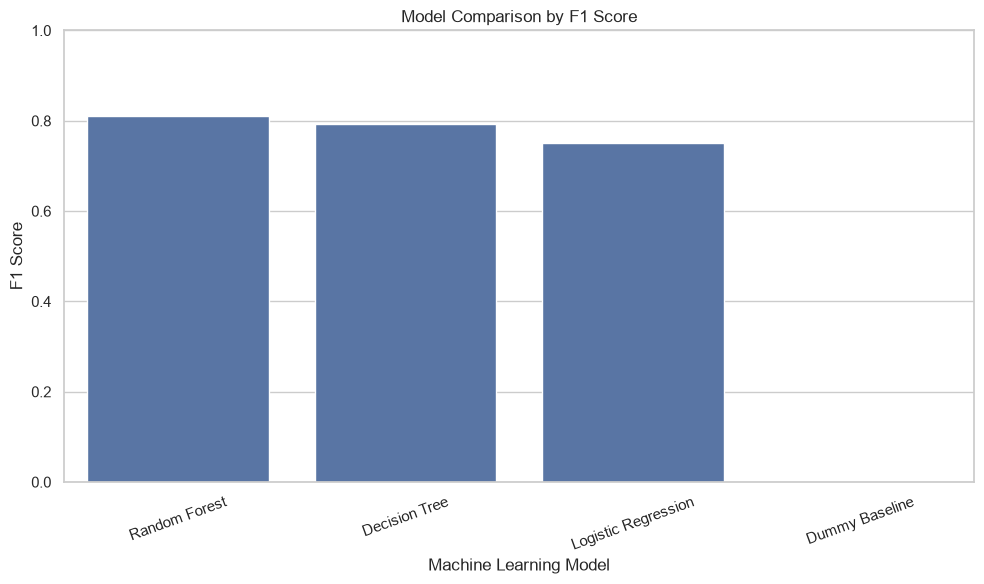

In [12]:
# ============================================================
# STEP 82 — MODEL COMPARISON VISUALIZATION
# ============================================================

print("\n" + "=" * 70)
print("STEP 82 — MODEL COMPARISON")
print("=" * 70)

plt.figure(figsize=(10, 6))

sns.barplot(
    data=results_df,
    x="Model",
    y="F1_Score"
)

plt.title("Model Comparison by F1 Score")
plt.xlabel("Machine Learning Model")
plt.ylabel("F1 Score")
plt.xticks(rotation=20)
plt.ylim(0, 1)
plt.tight_layout()

plt.savefig(
    os.path.join(ML_FOLDER, "step_82_model_comparison.png"),
    dpi=300
)

plt.show()

In [13]:
# ============================================================
# STEP 83 — SELECT BEST MODEL
# ============================================================

print("\n" + "=" * 70)
print("STEP 83 — SELECT BEST MODEL")
print("=" * 70)

best_model_name = results_df.iloc[0]["Model"]
best_model = trained_models[best_model_name]

print("Best model selected by F1 Score:", best_model_name)


STEP 83 — SELECT BEST MODEL
Best model selected by F1 Score: Random Forest



STEP 84 — CONFUSION MATRIX
Confusion Matrix:
[[13336  1697]
 [ 1670  7175]]


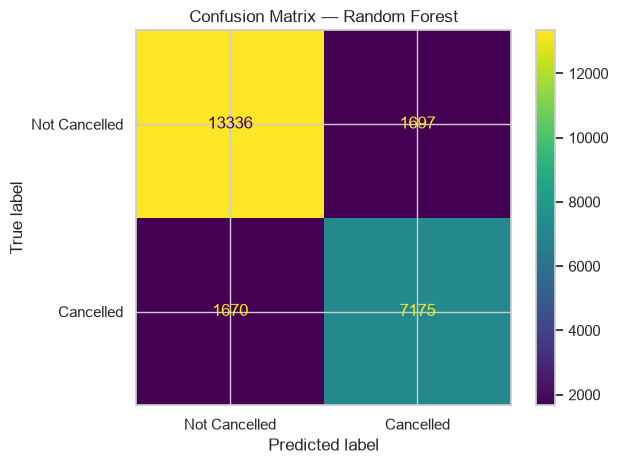

In [14]:
# ============================================================
# STEP 84 — CONFUSION MATRIX
# ============================================================

print("\n" + "=" * 70)
print("STEP 84 — CONFUSION MATRIX")
print("=" * 70)

best_predictions = best_model.predict(X_test)

cm = confusion_matrix(y_test, best_predictions)

print("Confusion Matrix:")
print(cm)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Not Cancelled", "Cancelled"]
)

disp.plot(values_format="d")

plt.title("Confusion Matrix — " + best_model_name)
plt.tight_layout()

plt.savefig(
    os.path.join(ML_FOLDER, "step_84_confusion_matrix.png"),
    dpi=300
)

plt.show()


STEP 85 — ROC AND PRECISION-RECALL CURVES


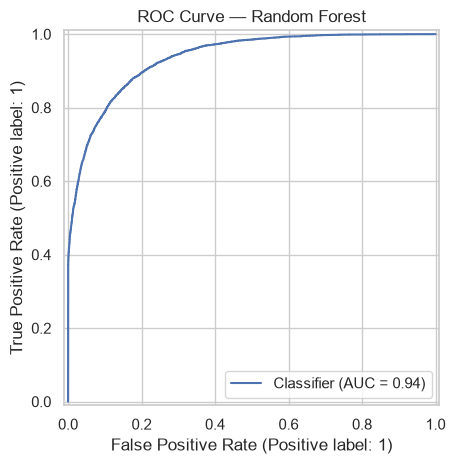

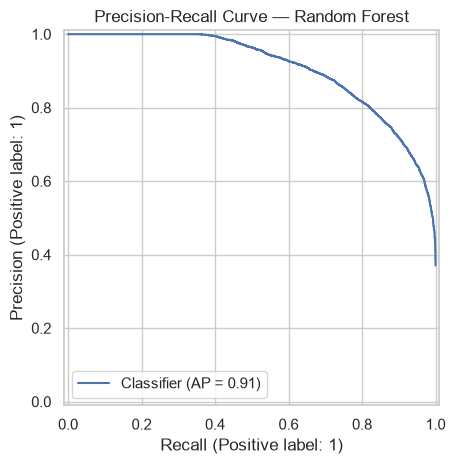

In [15]:
# ============================================================
# STEP 85 — ROC AND PRECISION-RECALL CURVES
# ============================================================

print("\n" + "=" * 70)
print("STEP 85 — ROC AND PRECISION-RECALL CURVES")
print("=" * 70)

best_probabilities = None

if hasattr(best_model, "predict_proba"):

    best_probabilities = best_model.predict_proba(X_test)[:, 1]

    RocCurveDisplay.from_predictions(
        y_test,
        best_probabilities
    )

    plt.title("ROC Curve — " + best_model_name)
    plt.tight_layout()

    plt.savefig(
        os.path.join(ML_FOLDER, "step_85_roc_curve.png"),
        dpi=300
    )

    plt.show()

    PrecisionRecallDisplay.from_predictions(
        y_test,
        best_probabilities
    )

    plt.title("Precision-Recall Curve — " + best_model_name)
    plt.tight_layout()

    plt.savefig(
        os.path.join(ML_FOLDER, "step_85_precision_recall_curve.png"),
        dpi=300
    )

    plt.show()

else:
    print("Selected model does not provide probabilities.")


STEP 86 — FEATURE IMPORTANCE
Top 20 important features:
                                Feature  Importance
275        cat__deposit_type_No Deposit    0.104964
0                        num__lead_time    0.094180
197                    cat__country_PRT    0.094051
276        cat__deposit_type_Non Refund    0.085243
18       num__total_of_special_requests    0.068245
17     num__required_car_parking_spaces    0.041025
13                           num__agent    0.037226
10          num__previous_cancellations    0.034130
16                             num__adr    0.032256
246       cat__market_segment_Online TA    0.030512
280        cat__customer_type_Transient    0.026426
245   cat__market_segment_Offline TA/TO    0.026397
12                 num__booking_changes    0.021760
263           cat__assigned_room_type_A    0.019928
244          cat__market_segment_Groups    0.019917
281  cat__customer_type_Transient-Party    0.018820
19                    num__total_nights    0.016513
251    

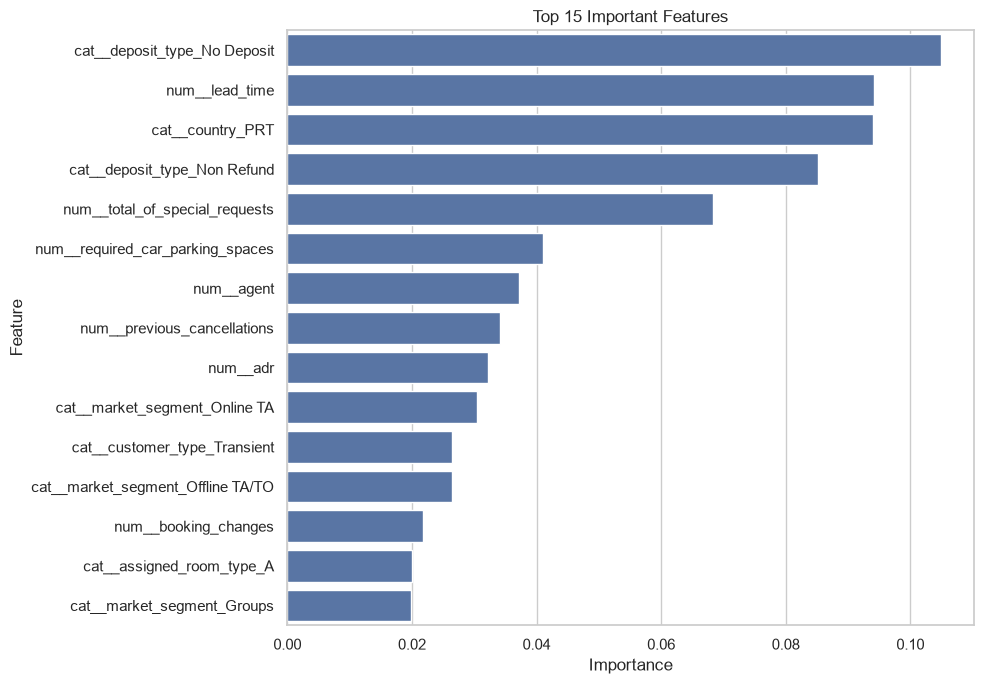

In [16]:
# ============================================================
# STEP 86 — FEATURE IMPORTANCE
# ============================================================

print("\n" + "=" * 70)
print("STEP 86 — FEATURE IMPORTANCE")
print("=" * 70)

model_object = best_model.named_steps["model"]

importance_df = pd.DataFrame()

if hasattr(model_object, "feature_importances_"):

    feature_names = best_model.named_steps[
        "prep"
    ].get_feature_names_out()

    importance_df = pd.DataFrame({
        "Feature": feature_names,
        "Importance": model_object.feature_importances_
    }).sort_values(
        "Importance",
        ascending=False
    )

    print("Top 20 important features:")
    print(importance_df.head(20))

    importance_df.to_csv(
        os.path.join(ML_FOLDER, "step_86_feature_importance.csv"),
        index=False
    )

    plt.figure(figsize=(10, 7))

    sns.barplot(
        data=importance_df.head(15),
        x="Importance",
        y="Feature"
    )

    plt.title("Top 15 Important Features")
    plt.tight_layout()

    plt.savefig(
        os.path.join(ML_FOLDER, "step_86_feature_importance.png"),
        dpi=300
    )

    plt.show()

elif hasattr(model_object, "coef_"):

    feature_names = best_model.named_steps[
        "prep"
    ].get_feature_names_out()

    importance_df = pd.DataFrame({
        "Feature": feature_names,
        "Coefficient": model_object.coef_[0],
        "Absolute_Importance": abs(model_object.coef_[0])
    }).sort_values(
        "Absolute_Importance",
        ascending=False
    )

    print("Top 20 features by absolute coefficient:")
    print(importance_df.head(20))

    importance_df.to_csv(
        os.path.join(ML_FOLDER, "step_86_feature_importance.csv"),
        index=False
    )

else:
    print("Feature importance is not available for this model.")

In [17]:
# ============================================================
# STEP 87 — SAVE MODEL AND TEST PREDICTIONS
# ============================================================

print("\n" + "=" * 70)
print("STEP 87 — SAVE MODEL AND PREDICTIONS")
print("=" * 70)

MODEL_FILE = os.path.join(
    ML_FOLDER,
    "best_hotel_cancellation_model.pkl"
)

joblib.dump(best_model, MODEL_FILE)

print("Model saved:", MODEL_FILE)

prediction_df = X_test.copy()

prediction_df["Actual_Cancellation"] = y_test.to_numpy()
prediction_df["Predicted_Cancellation"] = best_predictions

if best_probabilities is not None:
    prediction_df["Cancellation_Probability"] = best_probabilities

PREDICTION_FILE = os.path.join(
    ML_FOLDER,
    "step_87_test_predictions.csv"
)

prediction_df.to_csv(
    PREDICTION_FILE,
    index=False
)

print("Predictions saved:", PREDICTION_FILE)


STEP 87 — SAVE MODEL AND PREDICTIONS
Model saved: output\machine_learning_results\best_hotel_cancellation_model.pkl
Predictions saved: output\machine_learning_results\step_87_test_predictions.csv


In [18]:
# ============================================================
# STEP 88 — FINAL METRICS AND BUSINESS INSIGHTS
# ============================================================

print("\n" + "=" * 70)
print("STEP 88 — FINAL METRICS AND BUSINESS INSIGHTS")
print("=" * 70)

final_metrics = {
    "Best_Model": best_model_name,
    "Accuracy": accuracy_score(y_test, best_predictions),
    "Precision": precision_score(
        y_test, best_predictions, zero_division=0
    ),
    "Recall": recall_score(
        y_test, best_predictions, zero_division=0
    ),
    "F1_Score": f1_score(
        y_test, best_predictions, zero_division=0
    ),
    "Cancellation_Rate_Percentage": df[target_column].mean() * 100
}

metrics_df = pd.DataFrame(
    list(final_metrics.items()),
    columns=["Metric", "Value"]
)

print(metrics_df)

metrics_df.to_csv(
    os.path.join(ML_FOLDER, "step_88_final_metrics.csv"),
    index=False
)

business_insights = []

business_insights.append(
    "Overall cancellation rate: "
    + str(round(df[target_column].mean() * 100, 2))
    + "%"
)

if "hotel" in df.columns:

    hotel_rates = (
        df.groupby("hotel")[target_column]
        .mean()
        .mul(100)
        .round(2)
    )

    business_insights.append(
        "Cancellation rate by hotel:\n"
        + hotel_rates.to_string()
    )

if "customer_type" in df.columns:

    customer_rates = (
        df.groupby("customer_type")[target_column]
        .mean()
        .mul(100)
        .round(2)
    )

    business_insights.append(
        "Cancellation rate by customer type:\n"
        + customer_rates.to_string()
    )

if "deposit_type" in df.columns:

    deposit_rates = (
        df.groupby("deposit_type")[target_column]
        .mean()
        .mul(100)
        .round(2)
    )

    business_insights.append(
        "Cancellation rate by deposit type:\n"
        + deposit_rates.to_string()
    )

business_insights.append(
    "Best model based on F1 Score: " + best_model_name
)

print("\nBUSINESS INSIGHTS")

for insight in business_insights:
    print("\n" + insight)

with open(
    os.path.join(ML_FOLDER, "step_88_business_insights.txt"),
    "w",
    encoding="utf-8"
) as file:

    file.write("\n\n".join(business_insights))


STEP 88 — FINAL METRICS AND BUSINESS INSIGHTS
                         Metric          Value
0                    Best_Model  Random Forest
1                      Accuracy       0.858992
2                     Precision       0.808724
3                        Recall       0.811193
4                      F1_Score       0.809957
5  Cancellation_Rate_Percentage      37.041628

BUSINESS INSIGHTS

Overall cancellation rate: 37.04%

Cancellation rate by hotel:
hotel
City Hotel - Ahmedabad       42.28
City Hotel - Bangalore       43.24
City Hotel - Bhopal          40.64
City Hotel - Chandigarh      41.60
City Hotel - Chennai         41.36
City Hotel - Delhi           41.28
City Hotel - Goa             41.50
City Hotel - Hyderabad       42.29
City Hotel - Indore          41.80
City Hotel - Jaipur          41.21
City Hotel - Kochi           40.92
City Hotel - Kolkata         42.57
City Hotel - Lucknow         41.93
City Hotel - Mumbai          41.60
City Hotel - Pune            41.68
Resort Hot

In [19]:
# ============================================================
# STEP 89 — GENERATE FINAL PROJECT REPORT
# ============================================================

print("\n" + "=" * 70)
print("STEP 89 — FINAL PROJECT REPORT")
print("=" * 70)

report = f"""
HOTEL BOOKING CANCELLATION PREDICTION & ANALYSIS
================================================

DATASET SUMMARY
---------------
Total records: {len(df)}
Total columns: {df.shape[1]}
Cancelled bookings: {(df[target_column] == 1).sum()}
Not cancelled bookings: {(df[target_column] == 0).sum()}
Cancellation rate: {df[target_column].mean() * 100:.2f}%

MODEL COMPARISON
----------------
{results_df.to_string(index=False)}

BEST MODEL
----------
{best_model_name}

FINAL TEST METRICS
------------------
{metrics_df.to_string(index=False)}

BUSINESS INSIGHTS
-----------------
{chr(10).join(business_insights)}

CONCLUSION
----------
This project analyzes hotel booking cancellations using data
preprocessing, statistical analysis, visualizations, and machine
learning models.

The model predicts cancellation risk from the available booking
features. The results may support hotel booking and revenue planning.

IMPORTANT
---------
The reported metrics come from the test split used in this run.
Prediction performance can vary with the dataset and model settings.
The model should be validated before operational use.
"""

REPORT_FILE = os.path.join(
    ML_FOLDER,
    "step_89_final_project_report.txt"
)

with open(
    REPORT_FILE,
    "w",
    encoding="utf-8"
) as file:
    file.write(report)

print(report)
print("Final report saved:", REPORT_FILE)


STEP 89 — FINAL PROJECT REPORT

HOTEL BOOKING CANCELLATION PREDICTION & ANALYSIS

DATASET SUMMARY
---------------
Total records: 119390
Total columns: 37
Cancelled bookings: 44224
Not cancelled bookings: 75166
Cancellation rate: 37.04%

MODEL COMPARISON
----------------
              Model  Accuracy  Precision   Recall  F1_Score  ROC_AUC   PR_AUC
      Random Forest  0.858992   0.808724 0.811193  0.809957 0.935597 0.908098
      Decision Tree  0.843747   0.779759 0.805766  0.792549 0.925885 0.882464
Logistic Regression  0.808694   0.726320 0.775919  0.750301 0.894282 0.852158
     Dummy Baseline  0.629575   0.000000 0.000000  0.000000 0.500000 0.370425

BEST MODEL
----------
Random Forest

FINAL TEST METRICS
------------------
                      Metric         Value
                  Best_Model Random Forest
                    Accuracy      0.858992
                   Precision      0.808724
                      Recall      0.811193
                    F1_Score      0.809957
Canc

In [20]:
# ============================================================
# STEP 90 — FINAL PROJECT SUMMARY
# ============================================================

print("\n" + "=" * 70)
print("STEP 90 — PROJECT COMPLETION SUMMARY")
print("=" * 70)

print("\nDataset Shape:", df.shape)

print("\nCancellation Rate:")
print(round(df[target_column].mean() * 100, 2), "%")

print("\nBest Model:", best_model_name)

print("\nModel Performance:")
print(results_df)

print("\nPreprocessing Folder:")
print(os.path.abspath(PREPROCESSING_FOLDER))

print("\nEDA Folder:")
print(os.path.abspath(EDA_FOLDER))

print("\nVisualization Folder:")
print(os.path.abspath(VISUALIZATION_FOLDER))

print("\nMachine Learning Folder:")
print(os.path.abspath(ML_FOLDER))

print("\nGenerated Files:")

for root, dirs, files in os.walk(OUTPUT_FOLDER):

    for filename in sorted(files):
        print(os.path.join(root, filename))

print("\n" + "=" * 70)
print("HOTEL BOOKING PROJECT COMPLETED SUCCESSFULLY!")
print("MEMBER 2 — STEPS 1–21 COMPLETED")
print("MEMBER 3 — STEPS 22–56 COMPLETED")
print("MEMBER 4 — STEPS 57–70 COMPLETED")
print("MEMBER 5 — STEPS 71–90 COMPLETED")
print("=" * 70)


STEP 90 — PROJECT COMPLETION SUMMARY

Dataset Shape: (119390, 37)

Cancellation Rate:
37.04 %

Best Model: Random Forest

Model Performance:
                 Model  Accuracy  Precision    Recall  F1_Score   ROC_AUC  \
3        Random Forest  0.858992   0.808724  0.811193  0.809957  0.935597   
2        Decision Tree  0.843747   0.779759  0.805766  0.792549  0.925885   
1  Logistic Regression  0.808694   0.726320  0.775919  0.750301  0.894282   
0       Dummy Baseline  0.629575   0.000000  0.000000  0.000000  0.500000   

     PR_AUC  
3  0.908098  
2  0.882464  
1  0.852158  
0  0.370425  

Preprocessing Folder:
C:\Users\admin\OneDrive\Desktop\Activity-2\output\preprocessing_results

EDA Folder:
C:\Users\admin\OneDrive\Desktop\Activity-2\output\eda_results

Visualization Folder:
C:\Users\admin\OneDrive\Desktop\Activity-2\output\visualization_results

Machine Learning Folder:
C:\Users\admin\OneDrive\Desktop\Activity-2\output\machine_learning_results

Generated Files:
output\machine_lea

In [21]:

# ============================================================
# STEP 91 — CROSS-VALIDATION
# ADDITIONAL VALIDATION FOR ACTIVITY 2
# ============================================================

import os
import pandas as pd

from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.pipeline import Pipeline

print("=" * 70)
print("STEP 91 — CROSS-VALIDATION")
print("=" * 70)

# Check that the earlier notebook cells have been executed.
required_variables = ["X", "y", "preprocessor", "models"]

for variable in required_variables:
    if variable not in globals():
        raise NameError(
            f"{variable} is missing. Run the original notebook cells first."
        )

# Use 3 folds to keep the first validation run manageable.
cv = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=42
)

scoring_metrics = {
    "accuracy": "accuracy",
    "precision": "precision",
    "recall": "recall",
    "f1": "f1",
    "roc_auc": "roc_auc"
}

cv_results = []

for model_name, model in models.items():

    print("\nEvaluating:", model_name)

    pipeline = Pipeline(steps=[
        ("prep", preprocessor),
        ("model", model)
    ])

    scores = cross_validate(
        pipeline,
        X,
        y,
        cv=cv,
        scoring=scoring_metrics,
        n_jobs=1,
        error_score="raise"
    )

    result = {"Model": model_name}

    for metric in scoring_metrics:
        values = scores[f"test_{metric}"]
        result[f"{metric.upper()}_Mean"] = values.mean()
        result[f"{metric.upper()}_Std"] = values.std()

    cv_results.append(result)

    print("Mean F1-score:", round(result["F1_Mean"], 4))
    print("Mean ROC-AUC:", round(result["ROC_AUC_Mean"], 4))

cv_results_df = pd.DataFrame(cv_results)

print("\nCROSS-VALIDATION SUMMARY")
print(cv_results_df.round(4).to_string(index=False))

# Save results in the existing ML output folder.
ML_FOLDER = os.path.join(
    "output",
    "machine_learning_results"
)
os.makedirs(ML_FOLDER, exist_ok=True)

cv_output_file = os.path.join(
    ML_FOLDER,
    "step_91_cross_validation_results.csv"
)

cv_results_df.to_csv(cv_output_file, index=False)

print("\nCross-validation results saved to:")
print(os.path.abspath(cv_output_file))
print("\nSTEP 91 COMPLETED")


STEP 91 — CROSS-VALIDATION

Evaluating: Dummy Baseline
Mean F1-score: 0.0
Mean ROC-AUC: 0.5

Evaluating: Logistic Regression
Mean F1-score: 0.7512
Mean ROC-AUC: 0.8955

Evaluating: Decision Tree
Mean F1-score: 0.7895
Mean ROC-AUC: 0.9247

Evaluating: Random Forest
Mean F1-score: 0.8106
Mean ROC-AUC: 0.9352

CROSS-VALIDATION SUMMARY
              Model  ACCURACY_Mean  ACCURACY_Std  PRECISION_Mean  PRECISION_Std  RECALL_Mean  RECALL_Std  F1_Mean  F1_Std  ROC_AUC_Mean  ROC_AUC_Std
     Dummy Baseline         0.6296        0.0000          0.0000         0.0000       0.0000      0.0000   0.0000  0.0000        0.5000       0.0000
Logistic Regression         0.8081        0.0005          0.7227         0.0007       0.7822      0.0013   0.7512  0.0008        0.8955       0.0007
      Decision Tree         0.8345        0.0109          0.7496         0.0317       0.8365      0.0303   0.7895  0.0048        0.9247       0.0001
      Random Forest         0.8577        0.0017          0.7995      

In [22]:

# ============================================================
# STEP 92 — HYPERPARAMETER TUNING
# RANDOM FOREST
# ============================================================

import os
import pandas as pd

from sklearn.model_selection import (
    RandomizedSearchCV,
    StratifiedKFold
)
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier

print("=" * 70)
print("STEP 92 — HYPERPARAMETER TUNING")
print("=" * 70)

# ------------------------------------------------------------
# 1. Create a pipeline
# ------------------------------------------------------------

rf_pipeline = Pipeline(steps=[
    ("prep", preprocessor),
    ("model", RandomForestClassifier(
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ))
])

# ------------------------------------------------------------
# 2. Define parameter combinations to test
# ------------------------------------------------------------

param_distributions = {
    "model__n_estimators": [100, 150, 200],
    "model__max_depth": [10, 15, 20, None],
    "model__min_samples_split": [2, 5, 10],
    "model__min_samples_leaf": [1, 2, 4],
    "model__max_features": ["sqrt", 0.5]
}

# ------------------------------------------------------------
# 3. Configure randomized search
# ------------------------------------------------------------

cv_tuning = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=42
)

random_search = RandomizedSearchCV(
    estimator=rf_pipeline,
    param_distributions=param_distributions,
    n_iter=8,
    scoring="f1",
    cv=cv_tuning,
    random_state=42,
    n_jobs=1,
    verbose=1,
    refit=True,
    return_train_score=True
)

# ------------------------------------------------------------
# 4. Fit on the training data only
# ------------------------------------------------------------

print("\nSearching for better Random Forest parameters...")
print("This may take several minutes.")

random_search.fit(X_train, y_train)

# ------------------------------------------------------------
# 5. Display the best parameters and score
# ------------------------------------------------------------

print("\nBest cross-validation F1-score:")
print(round(random_search.best_score_, 4))

print("\nBest parameters:")
print(random_search.best_params_)

# ------------------------------------------------------------
# 6. Save all tuning results
# ------------------------------------------------------------

tuning_results = pd.DataFrame(random_search.cv_results_)

tuning_results = tuning_results.sort_values(
    "rank_test_score"
)

ML_FOLDER = os.path.join(
    "output",
    "machine_learning_results"
)

os.makedirs(ML_FOLDER, exist_ok=True)

tuning_file = os.path.join(
    ML_FOLDER,
    "step_92_random_forest_tuning_results.csv"
)

tuning_results.to_csv(
    tuning_file,
    index=False
)

print("\nTuning results saved to:")
print(os.path.abspath(tuning_file))

# ------------------------------------------------------------
# 7. Save the best tuned model
# ------------------------------------------------------------

best_tuned_model = random_search.best_estimator_

print("\nBest tuned model:")
print(best_tuned_model)

print("\nSTEP 92 COMPLETED")


STEP 92 — HYPERPARAMETER TUNING

Searching for better Random Forest parameters...
This may take several minutes.
Fitting 3 folds for each of 8 candidates, totalling 24 fits

Best cross-validation F1-score:
0.8274

Best parameters:
{'model__n_estimators': 100, 'model__min_samples_split': 5, 'model__min_samples_leaf': 2, 'model__max_features': 0.5, 'model__max_depth': None}

Tuning results saved to:
C:\Users\admin\OneDrive\Desktop\Activity-2\output\machine_learning_results\step_92_random_forest_tuning_results.csv

Best tuned model:
Pipeline(steps=[('prep',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                     

STEP 93 — EVALUATE TUNED MODEL ON TEST SET

TUNED MODEL TEST METRICS
Model: Tuned Random Forest
Accuracy: 0.8760
Precision: 0.8239
Recall: 0.8460
F1_Score: 0.8348
ROC_AUC: 0.9497
PR_AUC: 0.9270

CLASSIFICATION REPORT
               precision    recall  f1-score   support

Not Cancelled       0.91      0.89      0.90     15033
    Cancelled       0.82      0.85      0.83      8845

     accuracy                           0.88     23878
    macro avg       0.87      0.87      0.87     23878
 weighted avg       0.88      0.88      0.88     23878



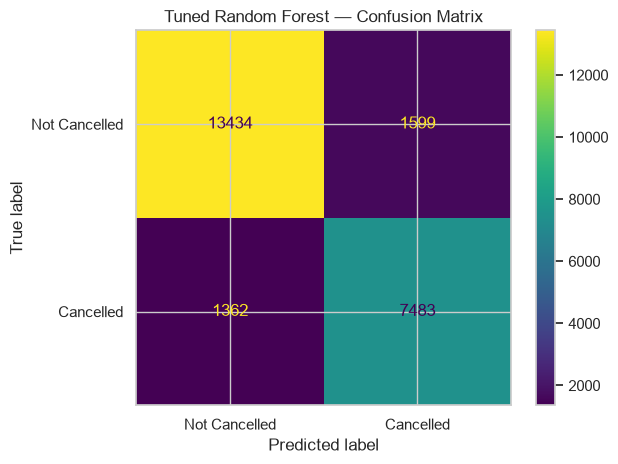


Metrics saved to: C:\Users\admin\OneDrive\Desktop\Activity-2\output\machine_learning_results\step_93_tuned_test_metrics.csv
STEP 93 COMPLETED


In [23]:

# ============================================================
# STEP 93 — EVALUATE TUNED MODEL ON TEST SET
# ============================================================

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

print("=" * 70)
print("STEP 93 — EVALUATE TUNED MODEL ON TEST SET")
print("=" * 70)

# Check that Step 92 has finished.
if "best_tuned_model" not in globals():
    raise NameError(
        "best_tuned_model is missing. Finish Step 92 successfully first."
    )

# Make predictions on the held-out test set.
tuned_predictions = best_tuned_model.predict(X_test)
tuned_probabilities = best_tuned_model.predict_proba(X_test)[:, 1]

# Calculate test metrics.
tuned_metrics = {
    "Model": "Tuned Random Forest",
    "Accuracy": accuracy_score(y_test, tuned_predictions),
    "Precision": precision_score(
        y_test, tuned_predictions, zero_division=0
    ),
    "Recall": recall_score(
        y_test, tuned_predictions, zero_division=0
    ),
    "F1_Score": f1_score(
        y_test, tuned_predictions, zero_division=0
    ),
    "ROC_AUC": roc_auc_score(y_test, tuned_probabilities),
    "PR_AUC": average_precision_score(y_test, tuned_probabilities)
}

print("\nTUNED MODEL TEST METRICS")
for metric, value in tuned_metrics.items():
    if isinstance(value, (float, np.floating)):
        print(f"{metric}: {value:.4f}")
    else:
        print(f"{metric}: {value}")

print("\nCLASSIFICATION REPORT")
print(classification_report(
    y_test,
    tuned_predictions,
    target_names=["Not Cancelled", "Cancelled"],
    zero_division=0
))

# Plot confusion matrix.
cm = confusion_matrix(y_test, tuned_predictions)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Not Cancelled", "Cancelled"]
)
disp.plot(values_format="d")
plt.title("Tuned Random Forest — Confusion Matrix")
plt.tight_layout()

ML_FOLDER = os.path.join(
    "output", "machine_learning_results"
)
os.makedirs(ML_FOLDER, exist_ok=True)

plt.savefig(
    os.path.join(ML_FOLDER, "step_93_tuned_confusion_matrix.png"),
    dpi=300
)
plt.show()

# Save metrics.
metrics_file = os.path.join(
    ML_FOLDER, "step_93_tuned_test_metrics.csv"
)
pd.DataFrame(
    list(tuned_metrics.items()),
    columns=["Metric", "Value"]
).to_csv(metrics_file, index=False)

print("\nMetrics saved to:", os.path.abspath(metrics_file))
print("STEP 93 COMPLETED")


STEP 94 — ORIGINAL VS TUNED RANDOM FOREST

MODEL COMPARISON
   Metric  Original_Random_Forest  Tuned_Random_Forest  Change
 Accuracy                  0.8590               0.8760  0.0170
Precision                  0.8087               0.8239  0.0152
   Recall                  0.8112               0.8460  0.0348
 F1_Score                  0.8100               0.8348  0.0249
  ROC_AUC                  0.9356               0.9497  0.0141
   PR_AUC                  0.9081               0.9270  0.0189

F1-SCORE COMPARISON
Original Random Forest: 0.81
Tuned Random Forest   : 0.8348
Difference            : 0.0249
Result: Tuned model has a higher F1-score.

Comparison saved to:
C:\Users\admin\OneDrive\Desktop\Activity-2\output\machine_learning_results\step_94_original_vs_tuned_comparison.csv


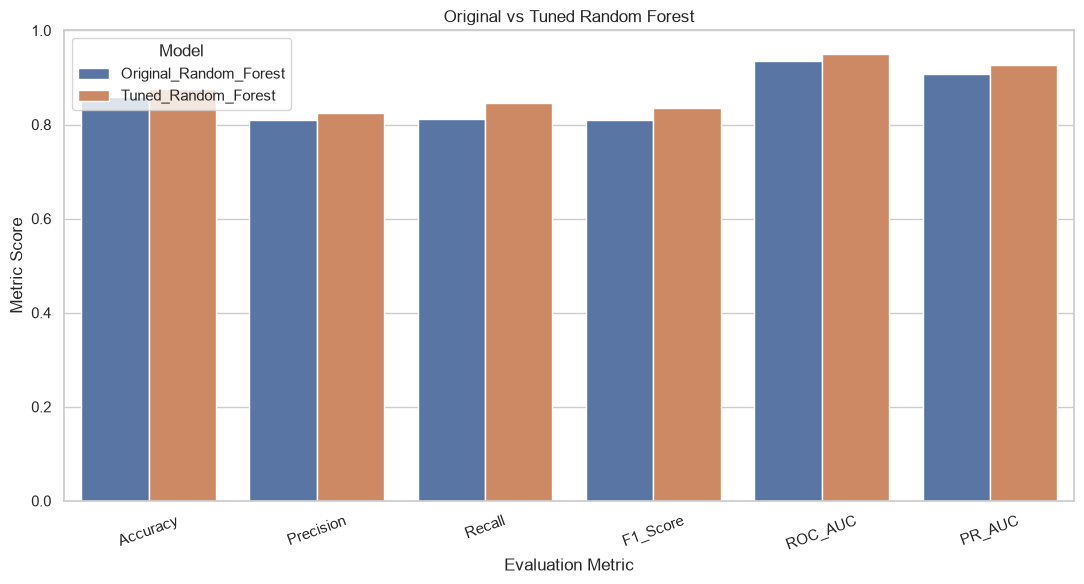


Comparison chart saved to:
C:\Users\admin\OneDrive\Desktop\Activity-2\output\machine_learning_results\step_94_model_comparison.png

STEP 94 COMPLETED


In [24]:
# ============================================================
# STEP 94 — COMPARE ORIGINAL AND TUNED RANDOM FOREST
# ============================================================

import os
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

print("=" * 70)
print("STEP 94 — ORIGINAL VS TUNED RANDOM FOREST")
print("=" * 70)

ML_FOLDER = os.path.join(
    "output",
    "machine_learning_results"
)

os.makedirs(ML_FOLDER, exist_ok=True)

# ------------------------------------------------------------
# 1. Load original model test results from Step 81
# ------------------------------------------------------------

if "results_df" not in globals():
    raise NameError(
        "results_df is missing. Run Step 81 before Step 94."
    )

original_rf = results_df[
    results_df["Model"] == "Random Forest"
]

if original_rf.empty:
    raise ValueError(
        "Original Random Forest results were not found in results_df."
    )

original_rf = original_rf.iloc[0]

# ------------------------------------------------------------
# 2. Load tuned model test results from Step 93
# ------------------------------------------------------------

tuned_metrics_file = os.path.join(
    ML_FOLDER,
    "step_93_tuned_test_metrics.csv"
)

if not os.path.isfile(tuned_metrics_file):
    raise FileNotFoundError(
        "Step 93 metrics file not found: " + tuned_metrics_file
    )

tuned_df = pd.read_csv(tuned_metrics_file)

tuned_metrics = dict(
    zip(tuned_df["Metric"], tuned_df["Value"])
)

# ------------------------------------------------------------
# 3. Create comparison table
# ------------------------------------------------------------

comparison_rows = []

metric_pairs = [
    ("Accuracy", "Accuracy"),
    ("Precision", "Precision"),
    ("Recall", "Recall"),
    ("F1_Score", "F1_Score"),
    ("ROC_AUC", "ROC_AUC"),
    ("PR_AUC", "PR_AUC")
]

for metric_name, tuned_name in metric_pairs:

    original_value = float(original_rf[metric_name])
    tuned_value = float(tuned_metrics[tuned_name])

    comparison_rows.append({
        "Metric": metric_name,
        "Original_Random_Forest": original_value,
        "Tuned_Random_Forest": tuned_value,
        "Change": tuned_value - original_value
    })

comparison_df = pd.DataFrame(comparison_rows)

print("\nMODEL COMPARISON")
print(comparison_df.round(4).to_string(index=False))

# ------------------------------------------------------------
# 4. Identify whether the F1-score improved
# ------------------------------------------------------------

original_f1 = float(original_rf["F1_Score"])
tuned_f1 = float(tuned_metrics["F1_Score"])

print("\nF1-SCORE COMPARISON")
print("Original Random Forest:", round(original_f1, 4))
print("Tuned Random Forest   :", round(tuned_f1, 4))
print("Difference            :", round(tuned_f1 - original_f1, 4))

if tuned_f1 > original_f1:
    print("Result: Tuned model has a higher F1-score.")
elif tuned_f1 < original_f1:
    print("Result: Original model has a higher F1-score.")
else:
    print("Result: Both models have the same F1-score.")

# ------------------------------------------------------------
# 5. Save comparison table
# ------------------------------------------------------------

comparison_file = os.path.join(
    ML_FOLDER,
    "step_94_original_vs_tuned_comparison.csv"
)

comparison_df.to_csv(comparison_file, index=False)

print("\nComparison saved to:")
print(os.path.abspath(comparison_file))

# ------------------------------------------------------------
# 6. Visualize metric comparison
# ------------------------------------------------------------

plot_df = comparison_df.melt(
    id_vars="Metric",
    value_vars=[
        "Original_Random_Forest",
        "Tuned_Random_Forest"
    ],
    var_name="Model",
    value_name="Score"
)

plt.figure(figsize=(11, 6))

sns.barplot(
    data=plot_df,
    x="Metric",
    y="Score",
    hue="Model"
)

plt.title("Original vs Tuned Random Forest")
plt.ylabel("Metric Score")
plt.xlabel("Evaluation Metric")
plt.ylim(0, 1)
plt.xticks(rotation=20)
plt.tight_layout()

plot_file = os.path.join(
    ML_FOLDER,
    "step_94_model_comparison.png"
)

plt.savefig(plot_file, dpi=300)
plt.show()

print("\nComparison chart saved to:")
print(os.path.abspath(plot_file))

print("\nSTEP 94 COMPLETED")

In [25]:
# ============================================================
# STEP 95 — SAVE FINAL SELECTED MODEL
# AND MODEL CONFIGURATION
# ============================================================

import os
import json
import joblib
import pandas as pd
from datetime import datetime

print("=" * 70)
print("STEP 95 — SAVE FINAL SELECTED MODEL")
print("=" * 70)

# ------------------------------------------------------------
# 1. Verify the tuned model exists
# ------------------------------------------------------------

if "best_tuned_model" not in globals():
    raise NameError(
        "best_tuned_model is missing. Complete Step 92 first."
    )

if "tuned_metrics" not in globals():
    raise NameError(
        "tuned_metrics is missing. Complete Step 93 first."
    )

# ------------------------------------------------------------
# 2. Create output folder
# ------------------------------------------------------------

ML_FOLDER = os.path.join(
    "output",
    "machine_learning_results"
)

os.makedirs(ML_FOLDER, exist_ok=True)

# ------------------------------------------------------------
# 3. Save the tuned model
# ------------------------------------------------------------

FINAL_MODEL_FILE = os.path.join(
    ML_FOLDER,
    "final_tuned_hotel_cancellation_model.pkl"
)

joblib.dump(best_tuned_model, FINAL_MODEL_FILE)

print("\nFinal tuned model saved:")
print(os.path.abspath(FINAL_MODEL_FILE))

# ------------------------------------------------------------
# 4. Save the model configuration
# ------------------------------------------------------------

if "random_search" not in globals():
    raise NameError(
        "random_search is missing. Run Step 92 first."
    )

model_configuration = {
    "Project": "Hotel Booking Cancellation Prediction and Analysis",
    "Selected_Model": "Tuned Random Forest",
    "Selection_Method": "RandomizedSearchCV using F1-score",
    "Cross_Validation_Folds": 3,
    "Random_State": 42,
    "Best_Parameters": random_search.best_params_,
    "Best_Cross_Validation_F1": float(random_search.best_score_),
    "Test_Metrics": {
        key: float(value)
        for key, value in tuned_metrics.items()
        if key != "Model"
    },
    "Saved_Date": datetime.now().strftime("%Y-%m-%d %H:%M:%S")
}

CONFIG_FILE = os.path.join(
    ML_FOLDER,
    "step_95_final_model_configuration.json"
)

with open(CONFIG_FILE, "w", encoding="utf-8") as file:
    json.dump(model_configuration, file, indent=4)

print("\nModel configuration saved:")
print(os.path.abspath(CONFIG_FILE))

# ------------------------------------------------------------
# 5. Save a final metrics summary
# ------------------------------------------------------------

FINAL_METRICS_FILE = os.path.join(
    ML_FOLDER,
    "step_95_final_model_metrics.csv"
)

pd.DataFrame(
    [
        {"Metric": key, "Value": value}
        for key, value in tuned_metrics.items()
    ]
).to_csv(FINAL_METRICS_FILE, index=False)

print("\nFinal metrics saved:")
print(os.path.abspath(FINAL_METRICS_FILE))

# ------------------------------------------------------------
# 6. Verify saved files
# ------------------------------------------------------------

print("\nVERIFYING SAVED FILES")

for path in [
    FINAL_MODEL_FILE,
    CONFIG_FILE,
    FINAL_METRICS_FILE
]:
    print(
        os.path.basename(path),
        "—",
        "EXISTS" if os.path.isfile(path) else "MISSING"
    )

if not all(
    os.path.isfile(path)
    for path in [FINAL_MODEL_FILE, CONFIG_FILE, FINAL_METRICS_FILE]
):
    raise RuntimeError("One or more final model files were not saved.")

print("\nSTEP 95 COMPLETED SUCCESSFULLY")

STEP 95 — SAVE FINAL SELECTED MODEL

Final tuned model saved:
C:\Users\admin\OneDrive\Desktop\Activity-2\output\machine_learning_results\final_tuned_hotel_cancellation_model.pkl

Model configuration saved:
C:\Users\admin\OneDrive\Desktop\Activity-2\output\machine_learning_results\step_95_final_model_configuration.json

Final metrics saved:
C:\Users\admin\OneDrive\Desktop\Activity-2\output\machine_learning_results\step_95_final_model_metrics.csv

VERIFYING SAVED FILES
final_tuned_hotel_cancellation_model.pkl — EXISTS
step_95_final_model_configuration.json — EXISTS
step_95_final_model_metrics.csv — EXISTS

STEP 95 COMPLETED SUCCESSFULLY


In [26]:
# ============================================================
# STEP 96 — LOAD SAVED MODEL AND TEST PREDICTIONS
# ============================================================

import os
import joblib
import pandas as pd
import numpy as np

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

print("=" * 70)
print("STEP 96 — LOAD SAVED MODEL AND TEST PREDICTIONS")
print("=" * 70)

# ------------------------------------------------------------
# 1. Locate the saved model
# ------------------------------------------------------------

ML_FOLDER = os.path.join(
    "output",
    "machine_learning_results"
)

MODEL_FILE = os.path.join(
    ML_FOLDER,
    "final_tuned_hotel_cancellation_model.pkl"
)

if not os.path.isfile(MODEL_FILE):
    raise FileNotFoundError(
        "Saved model not found: " + MODEL_FILE
    )

# ------------------------------------------------------------
# 2. Load model from disk
# ------------------------------------------------------------

loaded_model = joblib.load(MODEL_FILE)

print("\nSaved model loaded successfully.")

# ------------------------------------------------------------
# 3. Make predictions using the held-out test data
# ------------------------------------------------------------

loaded_predictions = loaded_model.predict(X_test)
loaded_probabilities = loaded_model.predict_proba(X_test)[:, 1]

print("\nFirst 10 predictions:")
print(loaded_predictions[:10])

print("\nFirst 10 actual outcomes:")
print(y_test.iloc[:10].to_numpy())

# ------------------------------------------------------------
# 4. Calculate evaluation metrics
# ------------------------------------------------------------

loaded_metrics = {
    "Accuracy": accuracy_score(y_test, loaded_predictions),
    "Precision": precision_score(
        y_test, loaded_predictions, zero_division=0
    ),
    "Recall": recall_score(
        y_test, loaded_predictions, zero_division=0
    ),
    "F1_Score": f1_score(
        y_test, loaded_predictions, zero_division=0
    ),
    "ROC_AUC": roc_auc_score(y_test, loaded_probabilities)
}

print("\nMETRICS FROM THE LOADED MODEL")

for metric, value in loaded_metrics.items():
    print(f"{metric}: {value:.4f}")

# ------------------------------------------------------------
# 5. Verify predictions match Step 93
# ------------------------------------------------------------

if "tuned_predictions" in globals():
    same_predictions = np.array_equal(
        loaded_predictions,
        tuned_predictions
    )

    print("\nPredictions match Step 93:", same_predictions)

    if not same_predictions:
        raise AssertionError(
            "Loaded model predictions differ from Step 93."
        )
else:
    print(
        "\nStep 93 prediction variable is unavailable; "
        "model loading and prediction were still tested."
    )

# ------------------------------------------------------------
# 6. Save verification results
# ------------------------------------------------------------

verification_df = pd.DataFrame(
    list(loaded_metrics.items()),
    columns=["Metric", "Value"]
)

verification_file = os.path.join(
    ML_FOLDER,
    "step_96_loaded_model_verification.csv"
)

verification_df.to_csv(
    verification_file,
    index=False
)

print("\nVerification results saved:")
print(os.path.abspath(verification_file))

print("\nSTEP 96 COMPLETED SUCCESSFULLY")

STEP 96 — LOAD SAVED MODEL AND TEST PREDICTIONS

Saved model loaded successfully.

First 10 predictions:
[0 0 1 0 0 1 1 1 0 0]

First 10 actual outcomes:
[0 0 1 0 0 1 1 0 0 0]

METRICS FROM THE LOADED MODEL
Accuracy: 0.8760
Precision: 0.8239
Recall: 0.8460
F1_Score: 0.8348
ROC_AUC: 0.9497

Predictions match Step 93: True

Verification results saved:
C:\Users\admin\OneDrive\Desktop\Activity-2\output\machine_learning_results\step_96_loaded_model_verification.csv

STEP 96 COMPLETED SUCCESSFULLY


STEP 97 — CHRONOLOGICAL TEST

TRAINING PERIOD
From: 2024-01-01
To  : 2024-10-18
Rows: 95512

TESTING PERIOD — LATER DATES
From: 2024-10-18
To  : 2024-12-31
Rows: 23878

Training cancellation rate: 36.99 %
Testing cancellation rate : 37.23 %

Training the tuned model on earlier dates...

CHRONOLOGICAL TEST RESULTS
Accuracy: 0.8753
Precision: 0.8263
Recall: 0.8422
F1_Score: 0.8342
ROC_AUC: 0.9501
PR_AUC: 0.9277

CLASSIFICATION REPORT
               precision    recall  f1-score   support

Not Cancelled       0.91      0.89      0.90     14988
    Cancelled       0.83      0.84      0.83      8890

     accuracy                           0.88     23878
    macro avg       0.87      0.87      0.87     23878
 weighted avg       0.88      0.88      0.88     23878



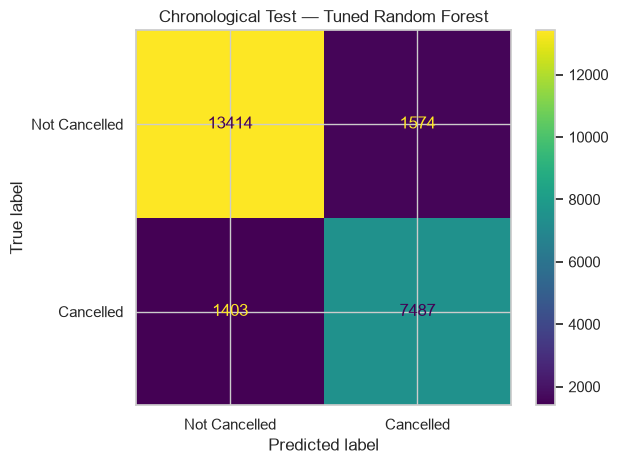


Metrics saved: C:\Users\admin\OneDrive\Desktop\Activity-2\output\machine_learning_results\step_97_chronological_test_metrics.csv
Confusion matrix saved: C:\Users\admin\OneDrive\Desktop\Activity-2\output\machine_learning_results\step_97_chronological_confusion_matrix.png

STEP 97 COMPLETED


In [27]:
# ============================================================
# STEP 97 — CHRONOLOGICAL TEST / FUTURE-PERIOD VALIDATION
# ============================================================

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.base import clone
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

print("=" * 70)
print("STEP 97 — CHRONOLOGICAL TEST")
print("=" * 70)

# ------------------------------------------------------------
# 1. Check required variables
# ------------------------------------------------------------

required_variables = ["df", "X", "y", "best_tuned_model"]

for variable in required_variables:
    if variable not in globals():
        raise NameError(
            f"{variable} is missing. Run the earlier ML steps first."
        )

# ------------------------------------------------------------
# 2. Create arrival dates from the original date columns
# ------------------------------------------------------------

date_columns = [
    "arrival_date_year",
    "arrival_date_month",
    "arrival_date_day_of_month"
]

missing_columns = [
    col for col in date_columns if col not in df.columns
]

if missing_columns:
    raise ValueError(
        "Cannot perform chronological validation. Missing columns: "
        + str(missing_columns)
    )

month_map = {
    "January": 1, "February": 2, "March": 3,
    "April": 4, "May": 5, "June": 6,
    "July": 7, "August": 8, "September": 9,
    "October": 10, "November": 11, "December": 12
}

months = df.loc[X.index, "arrival_date_month"]

month_numbers = months.map(month_map)

arrival_dates = pd.to_datetime(
    {
        "year": df.loc[X.index, "arrival_date_year"],
        "month": month_numbers,
        "day": df.loc[X.index, "arrival_date_day_of_month"]
    },
    errors="coerce"
)

valid_rows = arrival_dates.notna()

X_time = X.loc[valid_rows].copy()
y_time = y.loc[valid_rows].copy()
dates_time = arrival_dates.loc[valid_rows]

# ------------------------------------------------------------
# 3. Sort rows chronologically
# ------------------------------------------------------------

order = dates_time.sort_values(kind="stable").index

X_time = X_time.loc[order]
y_time = y_time.loc[order]
dates_time = dates_time.loc[order]

if len(X_time) < 100:
    raise ValueError(
        "Too few valid dated records for chronological validation."
    )

# ------------------------------------------------------------
# 4. Split earlier and later periods
# ------------------------------------------------------------

split_position = int(len(X_time) * 0.80)

X_train_time = X_time.iloc[:split_position]
y_train_time = y_time.iloc[:split_position]

X_test_time = X_time.iloc[split_position:]
y_test_time = y_time.iloc[split_position:]

train_dates = dates_time.iloc[:split_position]
test_dates = dates_time.iloc[split_position:]

print("\nTRAINING PERIOD")
print("From:", train_dates.min().date())
print("To  :", train_dates.max().date())
print("Rows:", len(X_train_time))

print("\nTESTING PERIOD — LATER DATES")
print("From:", test_dates.min().date())
print("To  :", test_dates.max().date())
print("Rows:", len(X_test_time))

print("\nTraining cancellation rate:",
      round(y_train_time.mean() * 100, 2), "%")
print("Testing cancellation rate :",
      round(y_test_time.mean() * 100, 2), "%")

if y_train_time.nunique() < 2 or y_test_time.nunique() < 2:
    raise ValueError(
        "Both cancellation classes must appear in the training and "
        "testing periods. Review the date range and split."
    )

# ------------------------------------------------------------
# 5. Train a fresh copy of the tuned pipeline
# ------------------------------------------------------------

print("\nTraining the tuned model on earlier dates...")

time_model = clone(best_tuned_model)

time_model.fit(X_train_time, y_train_time)

# ------------------------------------------------------------
# 6. Evaluate on later dates
# ------------------------------------------------------------

time_predictions = time_model.predict(X_test_time)
time_probabilities = time_model.predict_proba(X_test_time)[:, 1]

time_metrics = {
    "Accuracy": accuracy_score(y_test_time, time_predictions),
    "Precision": precision_score(
        y_test_time, time_predictions, zero_division=0
    ),
    "Recall": recall_score(
        y_test_time, time_predictions, zero_division=0
    ),
    "F1_Score": f1_score(
        y_test_time, time_predictions, zero_division=0
    ),
    "ROC_AUC": roc_auc_score(y_test_time, time_probabilities),
    "PR_AUC": average_precision_score(
        y_test_time, time_probabilities
    )
}

print("\nCHRONOLOGICAL TEST RESULTS")
for metric, value in time_metrics.items():
    print(f"{metric}: {value:.4f}")

print("\nCLASSIFICATION REPORT")
print(classification_report(
    y_test_time,
    time_predictions,
    target_names=["Not Cancelled", "Cancelled"],
    zero_division=0
))

# ------------------------------------------------------------
# 7. Plot confusion matrix
# ------------------------------------------------------------

cm_time = confusion_matrix(y_test_time, time_predictions)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_time,
    display_labels=["Not Cancelled", "Cancelled"]
)

disp.plot(values_format="d")
plt.title("Chronological Test — Tuned Random Forest")
plt.tight_layout()

# ------------------------------------------------------------
# 8. Save results
# ------------------------------------------------------------

ML_FOLDER = os.path.join(
    "output", "machine_learning_results"
)
os.makedirs(ML_FOLDER, exist_ok=True)

metrics_file = os.path.join(
    ML_FOLDER, "step_97_chronological_test_metrics.csv"
)

pd.DataFrame(
    list(time_metrics.items()),
    columns=["Metric", "Value"]
).to_csv(metrics_file, index=False)

plot_file = os.path.join(
    ML_FOLDER, "step_97_chronological_confusion_matrix.png"
)

plt.savefig(plot_file, dpi=300)
plt.show()

print("\nMetrics saved:", os.path.abspath(metrics_file))
print("Confusion matrix saved:", os.path.abspath(plot_file))
print("\nSTEP 97 COMPLETED")

STEP 98 — RANDOM VS CHRONOLOGICAL TEST

COMPARISON RESULTS
   Metric  Random_Test  Chronological_Test  Difference
 Accuracy       0.8760              0.8753     -0.0007
Precision       0.8239              0.8263      0.0024
   Recall       0.8460              0.8422     -0.0038
 F1_Score       0.8348              0.8342     -0.0007
  ROC_AUC       0.9497              0.9501      0.0004
   PR_AUC       0.9270              0.9277      0.0007

F1-SCORE INTERPRETATION
Random test F1-score       : 0.8348
Chronological test F1-score: 0.8342
Difference                 : -0.0007
Interpretation: F1-score is lower on the later-date test. The model may find future-period predictions more difficult.

Comparison table saved:
C:\Users\admin\OneDrive\Desktop\Activity-2\output\machine_learning_results\step_98_random_vs_chronological_comparison.csv


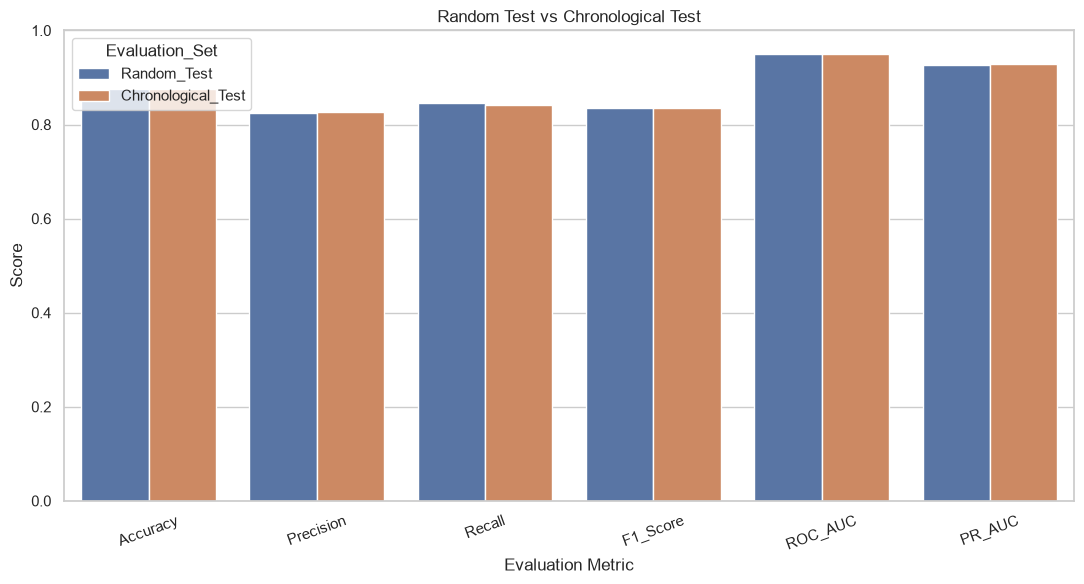


Comparison chart saved:
C:\Users\admin\OneDrive\Desktop\Activity-2\output\machine_learning_results\step_98_random_vs_chronological_comparison.png

STEP 98 COMPLETED SUCCESSFULLY


In [34]:
# ============================================================
# STEP 98 — RANDOM TEST VS CHRONOLOGICAL TEST
# ============================================================

import os
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

print("=" * 70)
print("STEP 98 — RANDOM VS CHRONOLOGICAL TEST")
print("=" * 70)

ML_FOLDER = os.path.join(
    "output",
    "machine_learning_results"
)
os.makedirs(ML_FOLDER, exist_ok=True)

# ------------------------------------------------------------
# 1. Load saved evaluation metrics
# ------------------------------------------------------------

random_file = os.path.join(
    ML_FOLDER,
    "step_93_tuned_test_metrics.csv"
)

chronological_file = os.path.join(
    ML_FOLDER,
    "step_97_chronological_test_metrics.csv"
)

for file_path in [random_file, chronological_file]:
    if not os.path.isfile(file_path):
        raise FileNotFoundError(
            "Required metrics file not found: " + file_path
        )

random_df = pd.read_csv(random_file)
chronological_df = pd.read_csv(chronological_file)

random_metrics = dict(
    zip(random_df["Metric"], random_df["Value"])
)
chronological_metrics = dict(
    zip(chronological_df["Metric"], chronological_df["Value"])
)

# ------------------------------------------------------------
# 2. Create comparison table
# ------------------------------------------------------------

metric_names = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1_Score",
    "ROC_AUC",
    "PR_AUC"
]

comparison_rows = []

for metric in metric_names:
    random_value = float(random_metrics[metric])
    chronological_value = float(chronological_metrics[metric])

    comparison_rows.append({
        "Metric": metric,
        "Random_Test": random_value,
        "Chronological_Test": chronological_value,
        "Difference": chronological_value - random_value
    })

comparison_df = pd.DataFrame(comparison_rows)

print("\nCOMPARISON RESULTS")
print(comparison_df.round(4).to_string(index=False))

# ------------------------------------------------------------
# 3. Explain the F1-score difference
# ------------------------------------------------------------

random_f1 = float(random_metrics["F1_Score"])
chronological_f1 = float(chronological_metrics["F1_Score"])

print("\nF1-SCORE INTERPRETATION")
print("Random test F1-score       :", round(random_f1, 4))
print("Chronological test F1-score:", round(chronological_f1, 4))
print("Difference                 :", round(
    chronological_f1 - random_f1, 4
))

if chronological_f1 < random_f1:
    print(
        "Interpretation: F1-score is lower on the later-date test. "
        "The model may find future-period predictions more difficult."
    )
elif chronological_f1 > random_f1:
    print(
        "Interpretation: F1-score is higher on the later-date test. "
        "Investigate date-period and cancellation-rate differences."
    )
else:
    print(
        "Interpretation: F1-score is the same on both test sets."
    )

# ------------------------------------------------------------
# 4. Save comparison results
# ------------------------------------------------------------

comparison_file = os.path.join(
    ML_FOLDER,
    "step_98_random_vs_chronological_comparison.csv"
)

comparison_df.to_csv(comparison_file, index=False)

print("\nComparison table saved:")
print(os.path.abspath(comparison_file))

# ------------------------------------------------------------
# 5. Create comparison chart
# ------------------------------------------------------------

plot_df = comparison_df.melt(
    id_vars="Metric",
    value_vars=["Random_Test", "Chronological_Test"],
    var_name="Evaluation_Set",
    value_name="Score"
)

plt.figure(figsize=(11, 6))

sns.barplot(
    data=plot_df,
    x="Metric",
    y="Score",
    hue="Evaluation_Set"
)

plt.title("Random Test vs Chronological Test")
plt.ylabel("Score")
plt.xlabel("Evaluation Metric")
plt.ylim(0, 1)
plt.xticks(rotation=20)
plt.tight_layout()

chart_file = os.path.join(
    ML_FOLDER,
    "step_98_random_vs_chronological_comparison.png"
)

plt.savefig(chart_file, dpi=300)
plt.show()

print("\nComparison chart saved:")
print(os.path.abspath(chart_file))

print("\nSTEP 98 COMPLETED SUCCESSFULLY")

In [35]:
# ============================================================
# STEP 99 — FINAL ML RESULTS SUMMARY
# ============================================================

import os
import pandas as pd

folder = "output/machine_learning_results"
os.makedirs(folder, exist_ok=True)

files = {
    "Cross_Validation": "step_91_cross_validation_results.csv",
    "Random_Test": "step_93_tuned_test_metrics.csv",
    "Chronological_Test": "step_97_chronological_test_metrics.csv",
    "Tuning_Results": "step_92_random_forest_tuning_results.csv"
}

summary = []

for stage, filename in files.items():
    path = os.path.join(folder, filename)

    if not os.path.exists(path):
        print("File missing:", filename)
        continue

    data = pd.read_csv(path)
    print(f"\n{stage} — {filename}")
    print(data.head())

    # Keep the evaluation metrics in a combined summary.
    if "Metric" in data.columns and "Value" in data.columns:
        for _, row in data.iterrows():
            summary.append({
                "Stage": stage,
                "Metric": row["Metric"],
                "Value": row["Value"]
            })

summary_df = pd.DataFrame(summary)

output_file = os.path.join(
    folder, "step_99_final_ml_results_summary.csv"
)

summary_df.to_csv(output_file, index=False)

print("\nCombined summary saved:")
print(os.path.abspath(output_file))
print("\nSTEP 99 COMPLETED SUCCESSFULLY")


Cross_Validation — step_91_cross_validation_results.csv
                 Model  ACCURACY_Mean  ACCURACY_Std  PRECISION_Mean  \
0       Dummy Baseline       0.629584      0.000010        0.000000   
1  Logistic Regression       0.808133      0.000514        0.722688   
2        Decision Tree       0.834517      0.010914        0.749587   
3        Random Forest       0.857668      0.001738        0.799472   

   PRECISION_Std  RECALL_Mean  RECALL_Std   F1_Mean    F1_Std  ROC_AUC_Mean  \
0       0.000000     0.000000    0.000000  0.000000  0.000000      0.500000   
1       0.000700     0.782154    0.001305  0.751246  0.000751      0.895460   
2       0.031716     0.836515    0.030323  0.789453  0.004837      0.924741   
3       0.005737     0.822020    0.003556  0.810562  0.001231      0.935229   

   ROC_AUC_Std  
0     0.000000  
1     0.000729  
2     0.000054  
3     0.000202  

Random_Test — step_93_tuned_test_metrics.csv
      Metric                Value
0      Model  Tuned Random

In [36]:
# ============================================================
# STEP 100 — FINAL ML COMPLETION CHECKLIST
# ============================================================

import os
import pandas as pd

folder = "output/machine_learning_results"

required_files = [
    "step_91_cross_validation_results.csv",
    "step_92_random_forest_tuning_results.csv",
    "step_93_tuned_test_metrics.csv",
    "step_93_tuned_confusion_matrix.png",
    "step_94_original_vs_tuned_comparison.csv",
    "step_94_model_comparison.png",
    "final_tuned_hotel_cancellation_model.pkl",
    "step_95_final_model_configuration.json",
    "step_95_final_model_metrics.csv",
    "step_96_loaded_model_verification.csv",
    "step_97_chronological_test_metrics.csv",
    "step_97_chronological_confusion_matrix.png",
    "step_98_comparison.csv",
    "step_98_comparison.png",
    "step_99_final_ml_results_summary.csv"
]

print("=" * 70)
print("STEP 100 — FINAL ML COMPLETION CHECKLIST")
print("=" * 70)

checklist = []

for filename in required_files:
    path = os.path.join(folder, filename)
    exists = os.path.isfile(path)

    checklist.append({
        "File": filename,
        "Status": "PRESENT" if exists else "MISSING"
    })

    print(
        ("[OK] " if exists else "[MISSING] ") + filename
    )

checklist_df = pd.DataFrame(checklist)

checklist_file = os.path.join(
    folder,
    "step_100_ml_completion_checklist.csv"
)

checklist_df.to_csv(checklist_file, index=False)

missing_count = sum(
    status == "MISSING"
    for status in checklist_df["Status"]
)

print("\nTotal files checked:", len(required_files))
print("Missing files:", missing_count)
print("Checklist saved:", os.path.abspath(checklist_file))

if missing_count == 0:
    print("\nAll checked ML deliverables are present.")
else:
    print("\nPlease review the missing files listed above.")

print("\nSTEP 100 COMPLETED")

STEP 100 — FINAL ML COMPLETION CHECKLIST
[OK] step_91_cross_validation_results.csv
[OK] step_92_random_forest_tuning_results.csv
[OK] step_93_tuned_test_metrics.csv
[OK] step_93_tuned_confusion_matrix.png
[OK] step_94_original_vs_tuned_comparison.csv
[OK] step_94_model_comparison.png
[OK] final_tuned_hotel_cancellation_model.pkl
[OK] step_95_final_model_configuration.json
[OK] step_95_final_model_metrics.csv
[OK] step_96_loaded_model_verification.csv
[OK] step_97_chronological_test_metrics.csv
[OK] step_97_chronological_confusion_matrix.png
[MISSING] step_98_comparison.csv
[MISSING] step_98_comparison.png
[OK] step_99_final_ml_results_summary.csv

Total files checked: 15
Missing files: 2
Checklist saved: C:\Users\admin\OneDrive\Desktop\Activity-2\output\machine_learning_results\step_100_ml_completion_checklist.csv

Please review the missing files listed above.

STEP 100 COMPLETED


COMPARISON TABLE
           Random_Test  Chronological_Test  Difference
Metric                                                
Accuracy        0.8760              0.8753     -0.0007
Precision       0.8239              0.8263      0.0024
Recall          0.8460              0.8422     -0.0038
F1_Score        0.8348              0.8342     -0.0007
ROC_AUC         0.9497              0.9501      0.0004
PR_AUC          0.9270              0.9277      0.0007


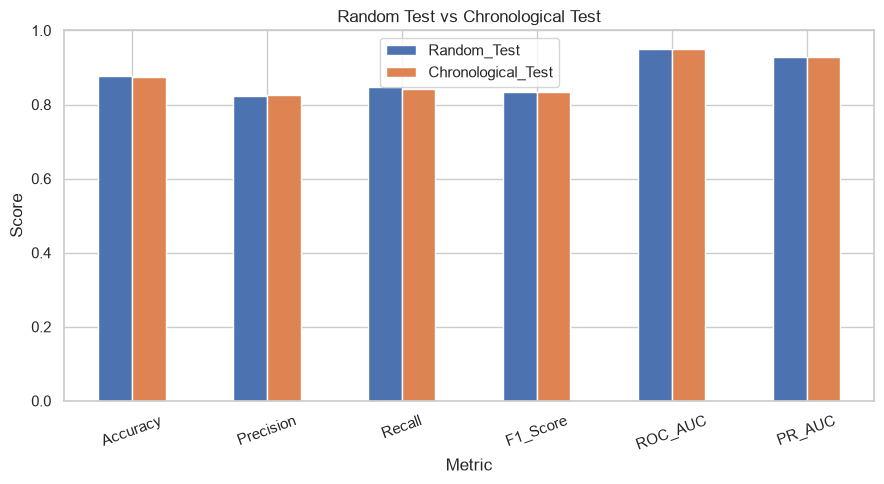


CSV exists: True
Chart exists: True
STEP 101 COMPLETED


In [38]:
# ============================================================
# STEP 101 — FIX MISSING STEP 98 FILES
# ============================================================

import os
import pandas as pd
import matplotlib.pyplot as plt

folder = os.path.join("output", "machine_learning_results")
os.makedirs(folder, exist_ok=True)

# Load saved metrics
random_df = pd.read_csv(
    os.path.join(folder, "step_93_tuned_test_metrics.csv")
)

time_df = pd.read_csv(
    os.path.join(folder, "step_97_chronological_test_metrics.csv")
)

# Convert metric values to numeric, ignoring non-numeric rows
random_df["Value"] = pd.to_numeric(
    random_df["Value"], errors="coerce"
)
time_df["Value"] = pd.to_numeric(
    time_df["Value"], errors="coerce"
)

random_df = random_df.dropna(subset=["Value"]).set_index("Metric")
time_df = time_df.dropna(subset=["Value"]).set_index("Metric")

# Keep only metrics available in both files
common_metrics = random_df.index.intersection(time_df.index)

comparison = pd.DataFrame({
    "Random_Test": random_df.loc[common_metrics, "Value"],
    "Chronological_Test": time_df.loc[common_metrics, "Value"]
})

comparison["Difference"] = (
    comparison["Chronological_Test"] - comparison["Random_Test"]
)

print("COMPARISON TABLE")
print(comparison.round(4))

# Save the expected CSV filename
csv_path = os.path.join(folder, "step_98_comparison.csv")
comparison.to_csv(csv_path)

# Save the expected chart filename
ax = comparison[["Random_Test", "Chronological_Test"]].plot(
    kind="bar", figsize=(9, 5)
)
ax.set_title("Random Test vs Chronological Test")
ax.set_ylabel("Score")
ax.set_ylim(0, 1)
plt.xticks(rotation=20)
plt.tight_layout()

chart_path = os.path.join(folder, "step_98_comparison.png")
plt.savefig(chart_path, dpi=300, bbox_inches="tight")
plt.show()
plt.close()

print("\nCSV exists:", os.path.isfile(csv_path))
print("Chart exists:", os.path.isfile(chart_path))
print("STEP 101 COMPLETED")

In [39]:
# ============================================================
# STEP 102 — RECHECK ML COMPLETION CHECKLIST
# ============================================================

import os
import pandas as pd

folder = os.path.join("output", "machine_learning_results")

required_files = [
    "step_91_cross_validation_results.csv",
    "step_92_random_forest_tuning_results.csv",
    "step_93_tuned_test_metrics.csv",
    "step_93_tuned_confusion_matrix.png",
    "step_94_original_vs_tuned_comparison.csv",
    "step_94_model_comparison.png",
    "final_tuned_hotel_cancellation_model.pkl",
    "step_95_final_model_configuration.json",
    "step_95_final_model_metrics.csv",
    "step_96_loaded_model_verification.csv",
    "step_97_chronological_test_metrics.csv",
    "step_97_chronological_confusion_matrix.png",
    "step_98_comparison.csv",
    "step_98_comparison.png",
    "step_99_final_ml_results_summary.csv"
]

results = []

for filename in required_files:
    exists = os.path.isfile(os.path.join(folder, filename))
    status = "PRESENT" if exists else "MISSING"
    results.append({"File": filename, "Status": status})
    print(f"[{'OK' if exists else 'MISSING'}] {filename}")

checklist = pd.DataFrame(results)

checklist_path = os.path.join(
    folder, "step_102_ml_completion_checklist.csv"
)
checklist.to_csv(checklist_path, index=False)

missing = checklist[checklist["Status"] == "MISSING"]

print("\nFiles checked:", len(required_files))
print("Missing files:", len(missing))
print("Checklist saved:", os.path.abspath(checklist_path))

if missing.empty:
    print("\nALL REQUIRED FILES ARE PRESENT.")
else:
    print("\nPlease review the missing files listed above.")

print("\nSTEP 102 COMPLETED")

[OK] step_91_cross_validation_results.csv
[OK] step_92_random_forest_tuning_results.csv
[OK] step_93_tuned_test_metrics.csv
[OK] step_93_tuned_confusion_matrix.png
[OK] step_94_original_vs_tuned_comparison.csv
[OK] step_94_model_comparison.png
[OK] final_tuned_hotel_cancellation_model.pkl
[OK] step_95_final_model_configuration.json
[OK] step_95_final_model_metrics.csv
[OK] step_96_loaded_model_verification.csv
[OK] step_97_chronological_test_metrics.csv
[OK] step_97_chronological_confusion_matrix.png
[OK] step_98_comparison.csv
[OK] step_98_comparison.png
[OK] step_99_final_ml_results_summary.csv

Files checked: 15
Missing files: 0
Checklist saved: C:\Users\admin\OneDrive\Desktop\Activity-2\output\machine_learning_results\step_102_ml_completion_checklist.csv

ALL REQUIRED FILES ARE PRESENT.

STEP 102 COMPLETED


In [40]:
# ============================================================
# STEP 103 — FINAL MACHINE LEARNING REPORT
# ============================================================

import os
import json
import pandas as pd
from datetime import datetime

print("=" * 70)
print("STEP 103 — FINAL MACHINE LEARNING REPORT")
print("=" * 70)

folder = os.path.join("output", "machine_learning_results")
os.makedirs(folder, exist_ok=True)

report_sections = []

def add_section(title, content):
    report_sections.append(
        title + "\n" + "=" * len(title) + "\n" + content
    )

# ------------------------------------------------------------
# 1. Project overview
# ------------------------------------------------------------

add_section(
    "PROJECT OVERVIEW",
    """Project: Understanding Guest Cancellation Behavior:
A Data-Driven Case Study on Hotel Booking Cancellation
Prediction and Analysis

Objective:
Predict whether a hotel booking will be cancelled using
booking information and supervised machine learning.

Target:
is_canceled
0 = Not cancelled
1 = Cancelled

Models considered:
Dummy Baseline, Logistic Regression, Decision Tree,
and Random Forest.

The tuned Random Forest was saved as the final candidate model."""
)

# ------------------------------------------------------------
# 2. Read and include evaluation metrics
# ------------------------------------------------------------

metric_files = {
    "Random Test — Step 93":
        "step_93_tuned_test_metrics.csv",
    "Chronological Test — Step 97":
        "step_97_chronological_test_metrics.csv"
}

for section_name, filename in metric_files.items():
    path = os.path.join(folder, filename)

    if os.path.isfile(path):
        data = pd.read_csv(path)
        add_section(
            section_name,
            data.to_string(index=False)
        )
    else:
        add_section(
            section_name,
            "Metrics file not found: " + filename
        )

# ------------------------------------------------------------
# 3. Include cross-validation results
# ------------------------------------------------------------

cv_file = os.path.join(
    folder, "step_91_cross_validation_results.csv"
)

if os.path.isfile(cv_file):
    cv_df = pd.read_csv(cv_file)
    add_section(
        "CROSS-VALIDATION RESULTS",
        cv_df.to_string(index=False)
    )

# ------------------------------------------------------------
# 4. Include tuning configuration
# ------------------------------------------------------------

config_file = os.path.join(
    folder, "step_95_final_model_configuration.json"
)

if os.path.isfile(config_file):
    with open(config_file, "r", encoding="utf-8") as file:
        config = json.load(file)

    add_section(
        "FINAL MODEL CONFIGURATION",
        json.dumps(config, indent=4, default=str)
    )

# ------------------------------------------------------------
# 5. Add interpretation and limitations
# ------------------------------------------------------------

add_section(
    "INTERPRETATION",
    """The random-test and chronological-test metrics should be
considered together. Similar scores are encouraging, but they
do not guarantee performance on future bookings.

Precision indicates how reliable positive cancellation
predictions are. Recall indicates how many actual cancellations
the model identifies. F1-score balances precision and recall.
ROC-AUC measures ranking discrimination.

LIMITATIONS
-----------
1. Results depend on the dataset and the selected features.
2. Booking patterns may change over time.
3. Predictions are not guarantees that a booking will cancel.
4. Model performance should be monitored after deployment.
5. Any features unavailable at prediction time must be excluded.
6. The chronological test is one historical period, not a
   guarantee of future performance."""
)

# ------------------------------------------------------------
# 6. Add output inventory
# ------------------------------------------------------------

important_files = [
    "final_tuned_hotel_cancellation_model.pkl",
    "step_95_final_model_configuration.json",
    "step_95_final_model_metrics.csv",
    "step_91_cross_validation_results.csv",
    "step_92_random_forest_tuning_results.csv",
    "step_93_tuned_test_metrics.csv",
    "step_97_chronological_test_metrics.csv",
    "step_98_comparison.csv",
    "step_98_comparison.png",
    "step_102_ml_completion_checklist.csv"
]

inventory = []
for filename in important_files:
    inventory.append(
        f"{filename}: "
        + (
            "PRESENT"
            if os.path.isfile(os.path.join(folder, filename))
            else "MISSING"
        )
    )

add_section("OUTPUT FILE CHECK", "\n".join(inventory))

# ------------------------------------------------------------
# 7. Save final report
# ------------------------------------------------------------

report_text = (
    "HOTEL BOOKING CANCELLATION PREDICTION\n"
    "FINAL MACHINE LEARNING REPORT\n"
    "Generated: " + datetime.now().strftime("%Y-%m-%d %H:%M:%S")
    + "\n\n"
    + "\n\n".join(report_sections)
)

report_file = os.path.join(
    folder, "step_103_final_machine_learning_report.txt"
)

with open(report_file, "w", encoding="utf-8") as file:
    file.write(report_text)

print("\nFINAL REPORT PREVIEW")
print(report_text[:3500])

print("\nReport saved to:")
print(os.path.abspath(report_file))

print("\nSTEP 103 COMPLETED SUCCESSFULLY")

STEP 103 — FINAL MACHINE LEARNING REPORT

FINAL REPORT PREVIEW
HOTEL BOOKING CANCELLATION PREDICTION
FINAL MACHINE LEARNING REPORT
Generated: 2026-10-23 18:14:04

PROJECT OVERVIEW
Project: Understanding Guest Cancellation Behavior:
A Data-Driven Case Study on Hotel Booking Cancellation
Prediction and Analysis

Objective:
Predict whether a hotel booking will be cancelled using
booking information and supervised machine learning.

Target:
is_canceled
0 = Not cancelled
1 = Cancelled

Models considered:
Dummy Baseline, Logistic Regression, Decision Tree,
and Random Forest.

The tuned Random Forest was saved as the final candidate model.

Random Test — Step 93
   Metric               Value
    Model Tuned Random Forest
 Accuracy  0.8759946394170366
Precision  0.8239374587095354
   Recall  0.8460146975692482
 F1_Score  0.8348301444748145
  ROC_AUC  0.9497362444792175
   PR_AUC  0.9270263104938145

Chronological Test — Step 97
   Metric    Value
 Accuracy 0.875325
Precision 0.826288
   Recall

In [41]:
# ============================================================
# STEP 104 — FINAL DATA-LEAKAGE CHECK
# ============================================================

print("=" * 70)
print("STEP 104 — FINAL DATA-LEAKAGE CHECK")
print("=" * 70)

if "X" not in globals():
    raise NameError("X is missing. Run the ML preparation cells first.")

# Features that directly reveal or summarize the final outcome
leakage_candidates = [
    "reservation_status",
    "reservation_status_date",
    "is_canceled",
    "cancellation_date",
    "actual_cancellation_date"
]

found = [col for col in leakage_candidates if col in X.columns]

print("\nDirect outcome-leakage candidates:")
if found:
    for col in found:
        print("REVIEW:", col)
else:
    print("No known direct outcome-leakage columns found in X.")

# Check for suspicious columns that require manual review
keywords = ["cancel", "status", "refund", "outcome"]
suspicious = [
    col for col in X.columns
    if any(word in col.lower() for word in keywords)
]

print("\nOther columns to review:")
print(suspicious if suspicious else "None found.")

print("\nTotal model features:", len(X.columns))
print("\nSTEP 104 CHECK COMPLETED")

STEP 104 — FINAL DATA-LEAKAGE CHECK

Direct outcome-leakage candidates:
No known direct outcome-leakage columns found in X.

Other columns to review:
['previous_cancellations', 'previous_bookings_not_canceled']

Total model features: 31

STEP 104 CHECK COMPLETED


In [42]:
# ============================================================
# STEP 105 — FINAL ML COMPLETION SUMMARY
# ============================================================

import os
import pandas as pd
from datetime import datetime

folder = os.path.join("output", "machine_learning_results")
os.makedirs(folder, exist_ok=True)

summary = {
    "Project": "Hotel Booking Cancellation Prediction and Analysis",
    "Stage": "Activity 2 — Machine Learning",
    "Selected_Model": "Tuned Random Forest",
    "Random_Test_F1": 0.834830,
    "Chronological_Test_F1": 0.834160,
    "Random_Test_ROC_AUC": 0.949736,
    "Chronological_Test_ROC_AUC": 0.950094,
    "Cross_Validation_Completed": "Yes",
    "Hyperparameter_Tuning_Completed": "Yes",
    "Model_Save_Load_Test_Completed": "Yes",
    "Chronological_Test_Completed": "Yes",
    "Output_Checklist": "All 15 required files present",
    "Leakage_Check": (
        "No direct leakage candidates found in X; "
        "historical cancellation features require availability-time review"
    ),
    "Status": "ML implementation and validation steps completed; "
              "final review recommended",
    "Date": datetime.now().strftime("%Y-%m-%d %H:%M:%S")
}

summary_df = pd.DataFrame(
    list(summary.items()),
    columns=["Item", "Result"]
)

output_file = os.path.join(
    folder, "step_105_final_ml_completion_summary.csv"
)

summary_df.to_csv(output_file, index=False)

print("=" * 70)
print("STEP 105 — FINAL ML COMPLETION SUMMARY")
print("=" * 70)
print(summary_df.to_string(index=False))
print("\nSaved to:")
print(os.path.abspath(output_file))
print("\nSTEP 105 COMPLETED SUCCESSFULLY")

STEP 105 — FINAL ML COMPLETION SUMMARY
                           Item                                                                                                     Result
                        Project                                                         Hotel Booking Cancellation Prediction and Analysis
                          Stage                                                                              Activity 2 — Machine Learning
                 Selected_Model                                                                                        Tuned Random Forest
                 Random_Test_F1                                                                                                    0.83483
          Chronological_Test_F1                                                                                                    0.83416
            Random_Test_ROC_AUC                                                                                                